# Chronological 60/20/20 split without detrending (MLO)

Optuna TPE (50 trials), chronological split, no detrending. To run Barrow, set `LOCATION = 'BRW'` in the settings cell and run the same notebook. Output: results/03_chronological_raw/.

**Part of:** Patidar & Patidar, *Predicting Daily Atmospheric CO$_2$ at Mauna Loa and Barrow: Trend-Aware Preprocessing and Chronological Validation* (JGR: Atmospheres, submitted). See the repository README for the run order.

Run from the `notebooks/` folder. Requires the packages in `requirements.txt`.


# CO₂ Prediction — Optuna Hyperparameter Tuning (v3) Sequential_Split Trees behaves erratically

**Location:** MLO or BRW — switch in Cell 3 only  
**Models:** Decision Tree · Random Forest · XGBoost · LSTM · BiLSTM  
**Tuning:** Optuna TPE Sampler + Median Pruner  
**Metrics:** MSE · RMSE · MAE · MAPE · R²  
**Feature set:** 9 engineered features (same as NB1 best config) — applied BEFORE tuning  

---
**Execution:** Run cells top to bottom. Each cell is labelled and self-contained.  
**Switch location:** Edit `LOCATION` in Cell 3 → Runtime → Run all.

---
## SECTION 1 — Environment Setup

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 1 — GPU CHECK
# ─────────────────────────────────────────────────────────────
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
if device.type == 'cuda':
    print('GPU Name:', torch.cuda.get_device_name(0))
else:
    print('No GPU — tree models fine on CPU; LSTM may be slower.')

In [ ]:
# Google Drive mounting removed: all paths are relative to the repository.
# Run this notebook from the `notebooks/` folder.
import os
print('Working directory:', os.getcwd())

Mounted at /content/drive
Drive mounted.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 3 — USER SETTINGS  ← ONLY EDIT THIS CELL
# ─────────────────────────────────────────────────────────────

# Location: 'MLO' = Mauna Loa  |  'BRW' = Barrow
LOCATION = 'MLO'

FILE_PATHS = {
    'MLO': '../data/processed/Imputed_BasePaper_MLO_CO2_CH4_N2O_1995_to_2022.csv',
    'BRW': '../data/processed/Imputed_BasePaper_BRW.csv',
}

# Optuna
N_TRIALS     = 50
CV_FOLDS     = 5
OPTUNA_SEED  = 42
N_JOBS       = -1

# LSTM
LSTM_MAX_EPOCHS = 50
LSTM_SEED       = 42

# Split
TEST_SIZE    = 0.2
RANDOM_STATE = 42

# Output folder on Drive
OUTPUT_DIR = f'../results/03_chronological_raw'   # output folder (relative to notebooks/)

FILE_PATH = FILE_PATHS[LOCATION]
print(f'Location  : {LOCATION}')
print(f'File      : {FILE_PATH}')
print(f'Output    : {OUTPUT_DIR}')

Location  : MLO
File      : /content/drive/MyDrive/CO2-prediction-project/DataForBasePaperComparison/Imputed_BasePaper_MLO_CO2_CH4_N2O_1995_to_2022.csv
Output    : /content/drive/MyDrive/CO2-prediction-project/Optuna_Results_MLO


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 4 — INSTALL DEPENDENCIES
# ─────────────────────────────────────────────────────────────
!pip install optuna --quiet
!pip install optuna-integration --quiet
print('Optuna installed.')

Optuna installed.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 5 — IMPORTS
# ─────────────────────────────────────────────────────────────
import os, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble        import RandomForestRegressor
from sklearn.tree            import DecisionTreeRegressor
from sklearn.preprocessing   import MinMaxScaler
from sklearn.metrics         import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

import xgboost as xgb

import optuna
from optuna.samplers import TPESampler
from optuna.pruners  import MedianPruner
optuna.logging.set_verbosity(optuna.logging.WARNING)

import tensorflow as tf
from tensorflow.keras.models     import Sequential
from tensorflow.keras.layers     import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks  import EarlyStopping
from matplotlib.patches import Patch

os.makedirs(OUTPUT_DIR, exist_ok=True)

print('All imports OK')
print(f'Optuna  : {optuna.__version__}')
print(f'TF      : {tf.__version__}')
print(f'XGBoost : {xgb.__version__}')

All imports OK
Optuna  : 4.8.0
TF      : 2.20.0
XGBoost : 3.2.0


---
## SECTION 2 — Data Loading & Feature Engineering
> Feature engineering is done **before** hyperparameter optimisation so every model is tuned on the same enriched 9-feature set.

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 6 — LOAD & PARSE RAW DATA
# Deep preprocessing matching NB1
# ─────────────────────────────────────────────────────────────
df_raw = pd.read_csv(FILE_PATH)
df_raw.columns = df_raw.columns.str.strip()
print('Columns:', df_raw.columns.tolist())
print('Raw shape:', df_raw.shape)

# Combine year/month/day → single datetime index
df_raw['day'] = pd.to_datetime(df_raw[['year', 'month', 'day']])
df_raw.drop(columns=['year', 'month'], inplace=True)
df_raw.sort_values('day', inplace=True)
df_raw.reset_index(drop=True, inplace=True)
df_raw.set_index('day', inplace=True)

# Reindex to continuous daily range — missing days become explicit NaN
full_idx = pd.date_range(df_raw.index.min(), df_raw.index.max(), freq='D')
df_raw   = df_raw.reindex(full_idx)
df_raw.index.name = 'day'

print(f'Date range : {df_raw.index.min().date()} -> {df_raw.index.max().date()}')
print(f'Total days : {len(df_raw)}')
print(f'NaN CO2    : {df_raw["CO2_value"].isna().sum()}')
df_raw.head()

Columns: ['year', 'month', 'day', 'CO2_value', 'CH4_value', 'N2O_value']
Raw shape: (9845, 6)
Date range : 1995-12-15 -> 2022-11-27
Total days : 9845
NaN CO2    : 0


,CO2_value,CH4_value,N2O_value
day,,,
1995-12-15,360.59,1764.21,311.547
1995-12-16,361.76,1783.36,311.542
1995-12-17,360.72,1762.18,311.862
1995-12-18,360.46,1760.24,312.380
1995-12-19,360.44,1760.78,311.192


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 7 — FEATURE ENGINEERING
# PrevDayCO2 (1-day lag) + 7-day rolling mean & std
# for CO2, CH4, N2O → 9 features total
# Applied BEFORE any optimisation
# ─────────────────────────────────────────────────────────────
data = df_raw.copy()

# Lag feature
data['PrevDayCO2'] = data['CO2_value'].shift(1)

# 7-day rolling mean & std
for col in ['CH4_value', 'N2O_value', 'CO2_value']:
    data[f'{col}_mean_7d'] = data[col].rolling(window=7, min_periods=1).mean()
    data[f'{col}_std_7d']  = data[col].rolling(window=7, min_periods=1).std()

data.dropna(inplace=True)

FEATURES = [
    'CH4_value',         'N2O_value',         'PrevDayCO2',
    'CH4_value_mean_7d', 'CH4_value_std_7d',
    'N2O_value_mean_7d', 'N2O_value_std_7d',
    'CO2_value_mean_7d', 'CO2_value_std_7d'
]
TARGET = 'CO2_value'

print(f'Features ({len(FEATURES)}) : {FEATURES}')
print(f'Target              : {TARGET}')
print(f'Dataset shape       : {data.shape}')

Features (9) : ['CH4_value', 'N2O_value', 'PrevDayCO2', 'CH4_value_mean_7d', 'CH4_value_std_7d', 'N2O_value_mean_7d', 'N2O_value_std_7d', 'CO2_value_mean_7d', 'CO2_value_std_7d']
Target              : CO2_value
Dataset shape       : (9844, 10)


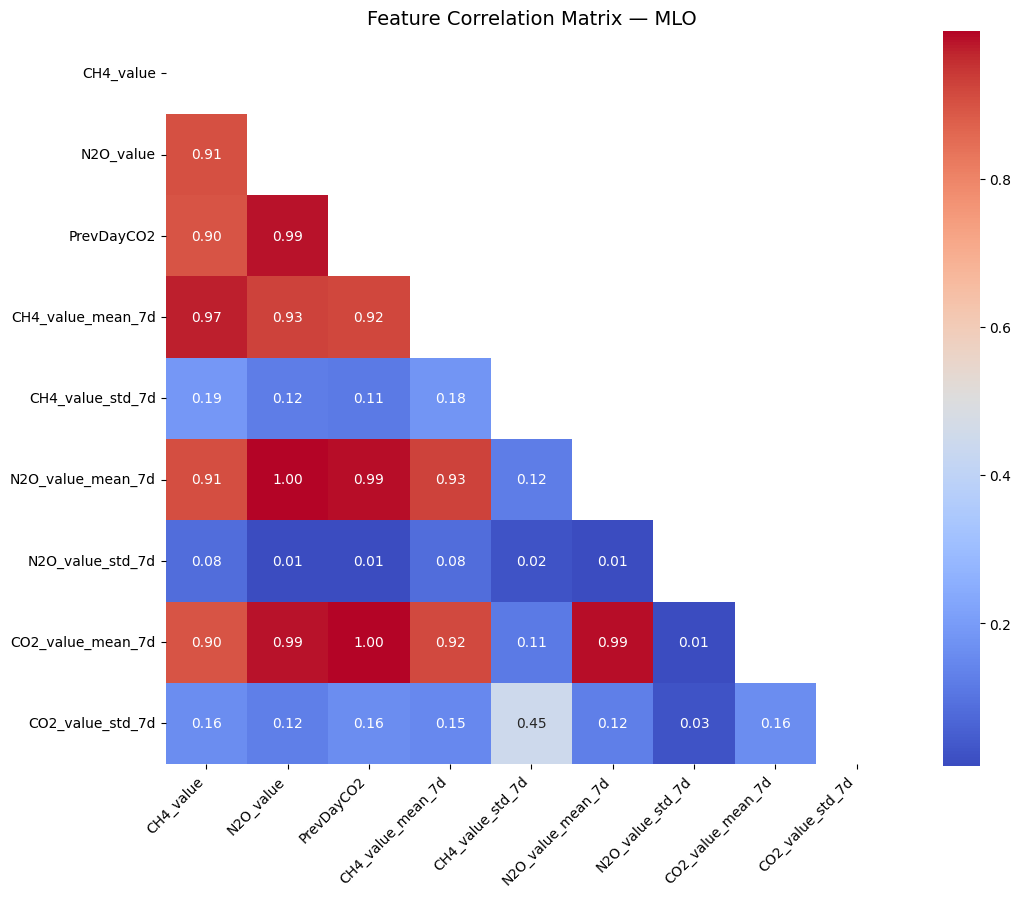

Heatmap saved.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 8 — CORRELATION HEATMAP
# Inspect engineered features before modelling
# ─────────────────────────────────────────────────────────────
corr = data[FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', cbar=True, square=True, annot_kws={'size': 10})
plt.xticks(fontsize=10, rotation=45, ha='right')
plt.yticks(fontsize=10)
plt.title(f'Feature Correlation Matrix — {LOCATION}', fontsize=14)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Correlation_{LOCATION}.png', dpi=150)
plt.show()
print('Heatmap saved.')

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 9 — SEQUENTIAL TRAIN / VAL / TEST SPLIT
# Chronological order preserved — no future leakage
# 60% train | 20% val | 20% test
# ─────────────────────────────────────────────────────────────
n = len(data)
train_end = int(n * 0.60)
val_end   = int(n * 0.80)

X = data[FEATURES]
y = data[TARGET]

X_train, y_train = X.iloc[:train_end],        y.iloc[:train_end]
X_val,   y_val   = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test,  y_test  = X.iloc[val_end:],          y.iloc[val_end:]

print(f'Train : {len(X_train):>5} samples  ({len(X_train)/n*100:.0f}%)  {X_train.index.min().date()} → {X_train.index.max().date()}')
print(f'Val   : {len(X_val):>5} samples  ({len(X_val)/n*100:.0f}%)  {X_val.index.min().date()} → {X_val.index.max().date()}')
print(f'Test  : {len(X_test):>5} samples  ({len(X_test)/n*100:.0f}%)  {X_test.index.min().date()} → {X_test.index.max().date()}')

Train :  5906 samples  (60%)  1995-12-16 → 2012-02-15
Val   :  1969 samples  (20%)  2012-02-16 → 2017-07-07
Test  :  1969 samples  (20%)  2017-07-08 → 2022-11-27


---
## SECTION 3 — Shared Metrics Helper

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 10 — compute_metrics() HELPER
# Computes MSE, RMSE, MAE, MAPE, R2 in one call.
# Used identically by every model below.
# ─────────────────────────────────────────────────────────────
def compute_metrics(y_true, y_pred, label=''):
    y_true = np.array(y_true).ravel()
    y_pred = np.array(y_pred).ravel()

    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # as %
    r2   = r2_score(y_true, y_pred)

    header = f'  [{label}]' if label else ''
    if header: print(header)
    print(f'  MSE  : {mse:.6f}')
    print(f'  RMSE : {rmse:.6f}')
    print(f'  MAE  : {mae:.6f}')
    print(f'  MAPE : {mape:.4f} %')
    print(f'  R2   : {r2:.6f}')

    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2}

# Shared KFold object — same across all tree models
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=OPTUNA_SEED)

# Shared bar chart colours
COLORS_ALL = ['#4C8BE8','#4C8BE8','#4C8BE8','#2EAF82','#2EAF82']
LEGEND_ELEMS = [Patch(facecolor='#4C8BE8', label='Tree Models'),
                Patch(facecolor='#2EAF82', label='Deep Learning')]

print('compute_metrics() ready.')
print('Shared KFold and colour palette ready.')

compute_metrics() ready.
Shared KFold and colour palette ready.


---
## SECTION 4 — Decision Tree (Optuna)

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 11 — DECISION TREE: DEFINE OPTUNA OBJECTIVE
# Search space mirrors NB2 Bayesian ranges (wide)
# ─────────────────────────────────────────────────────────────
def dt_objective(trial):
    params = {
        'max_depth'        : trial.suggest_int('max_depth', 1, 50),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 20),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
    }
    model  = DecisionTreeRegressor(**params, random_state=OPTUNA_SEED)
    scores = cross_val_score(model, X_train, y_train,
                             cv=kf, scoring='neg_mean_squared_error', n_jobs=N_JOBS)
    return -scores.mean()

print('Decision Tree objective defined.')

Decision Tree objective defined.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 12 — DECISION TREE: RUN OPTUNA STUDY
# ─────────────────────────────────────────────────────────────
print(f'Decision Tree Optuna study — {N_TRIALS} trials ...')

dt_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=OPTUNA_SEED),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=5),
    study_name=f'{LOCATION}_DT'
)
dt_study.optimize(dt_objective, n_trials=N_TRIALS, show_progress_bar=True)

dt_best_params = dt_study.best_params
print(f'Best params : {dt_best_params}')
print(f'Best CV MSE : {dt_study.best_value:.6f}')

Decision Tree Optuna study — 50 trials ...


  0%|          | 0/50 [00:00<?, ?it/s]

Best params : {'max_depth': 48, 'min_samples_split': 9, 'min_samples_leaf': 20, 'max_features': None}
Best CV MSE : 0.257736


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 13 — DECISION TREE: TRAIN FINAL MODEL & EVALUATE
# ─────────────────────────────────────────────────────────────
dt_final = DecisionTreeRegressor(**dt_best_params, random_state=OPTUNA_SEED)
dt_final.fit(X_train, y_train)
y_pred_dt = dt_final.predict(X_test)

print(f'\n==== DECISION TREE — {LOCATION} ====')
dt_metrics = compute_metrics(y_test, y_pred_dt, label='Test Set')

# CV metrics on train set
dt_cv_mse = cross_val_score(dt_final, X_train, y_train, cv=kf, scoring='neg_mean_squared_error',   n_jobs=N_JOBS)
dt_cv_mae = cross_val_score(dt_final, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error',  n_jobs=N_JOBS)
dt_cv_r2  = cross_val_score(dt_final, X_train, y_train, cv=kf, scoring='r2',                       n_jobs=N_JOBS)
print(f'  [CV Train]  MSE={-dt_cv_mse.mean():.4f}  MAE={-dt_cv_mae.mean():.4f}  R2={dt_cv_r2.mean():.6f}')


==== DECISION TREE — MLO ====
  [Test Set]
  MSE  : 359.028406
  RMSE : 18.948045
  MAE  : 18.406778
  MAPE : 4.4451 %
  R2   : -16.757046
  [CV Train]  MSE=0.2577  MAE=0.3638  R2=0.997065


---
## SECTION 5 — Random Forest (Optuna)

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 14 — RANDOM FOREST: DEFINE OPTUNA OBJECTIVE
# ─────────────────────────────────────────────────────────────
def rf_objective(trial):
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 10, 1000),
        'max_depth'        : trial.suggest_int('max_depth', 1, 50),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 20),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2']),
    }
    model  = RandomForestRegressor(**params, random_state=OPTUNA_SEED, n_jobs=N_JOBS)
    scores = cross_val_score(model, X_train, y_train,
                             cv=kf, scoring='neg_mean_squared_error', n_jobs=N_JOBS)
    return -scores.mean()

print('Random Forest objective defined.')

Random Forest objective defined.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 15 — RANDOM FOREST: RUN OPTUNA STUDY
# ─────────────────────────────────────────────────────────────
print(f'Random Forest Optuna study — {N_TRIALS} trials ...')

rf_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=OPTUNA_SEED),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=5),
    study_name=f'{LOCATION}_RF'
)
rf_study.optimize(rf_objective, n_trials=N_TRIALS, show_progress_bar=True)

rf_best_params = rf_study.best_params
print(f'Best params : {rf_best_params}')
print(f'Best CV MSE : {rf_study.best_value:.6f}')

Random Forest Optuna study — 50 trials ...


  0%|          | 0/50 [00:00<?, ?it/s]

Best params : {'n_estimators': 826, 'max_depth': 24, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2'}
Best CV MSE : 0.194786


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 16 — RANDOM FOREST: TRAIN FINAL MODEL & EVALUATE
# ─────────────────────────────────────────────────────────────
rf_final = RandomForestRegressor(**rf_best_params, random_state=OPTUNA_SEED, n_jobs=N_JOBS)
rf_final.fit(X_train, y_train)
y_pred_rf = rf_final.predict(X_test)

print(f'\n==== RANDOM FOREST — {LOCATION} ====')
rf_metrics = compute_metrics(y_test, y_pred_rf, label='Test Set')

rf_cv_mse = cross_val_score(rf_final, X_train, y_train, cv=kf, scoring='neg_mean_squared_error',   n_jobs=N_JOBS)
rf_cv_mae = cross_val_score(rf_final, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error',  n_jobs=N_JOBS)
rf_cv_r2  = cross_val_score(rf_final, X_train, y_train, cv=kf, scoring='r2',                       n_jobs=N_JOBS)
print(f'  [CV Train]  MSE={-rf_cv_mse.mean():.4f}  MAE={-rf_cv_mae.mean():.4f}  R2={rf_cv_r2.mean():.6f}')


==== RANDOM FOREST — MLO ====
  [Test Set]
  MSE  : 334.653222
  RMSE : 18.293530
  MAE  : 17.753540
  MAPE : 4.2871 %
  R2   : -15.551484
  [CV Train]  MSE=0.1948  MAE=0.3067  R2=0.997784


---
## SECTION 6 — XGBoost (Optuna)

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 17 — XGBOOST: DEFINE OPTUNA OBJECTIVE
# Wider than NB2: adds gamma, reg_alpha, reg_lambda
# ─────────────────────────────────────────────────────────────
def xgb_objective(trial):
    params = {
        'n_estimators'    : trial.suggest_int('n_estimators', 50, 1000),
        'max_depth'       : trial.suggest_int('max_depth', 1, 50),
        'learning_rate'   : trial.suggest_float('learning_rate', 1e-6, 1.0, log=True),
        'subsample'       : trial.suggest_float('subsample', 0.1, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.1, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma'           : trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
    }
    model  = xgb.XGBRegressor(**params, objective='reg:squarederror',
                               random_state=OPTUNA_SEED, verbosity=0)
    scores = cross_val_score(model, X_train, y_train,
                             cv=kf, scoring='neg_mean_squared_error', n_jobs=N_JOBS)
    return -scores.mean()

print('XGBoost objective defined.')

XGBoost objective defined.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 18 — XGBOOST: RUN OPTUNA STUDY
# ─────────────────────────────────────────────────────────────
print(f'XGBoost Optuna study — {N_TRIALS} trials ...')

xgb_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=OPTUNA_SEED),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=5),
    study_name=f'{LOCATION}_XGB'
)
xgb_study.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=True)

xgb_best_params = xgb_study.best_params
print(f'Best params : {xgb_best_params}')
print(f'Best CV MSE : {xgb_study.best_value:.6f}')

XGBoost Optuna study — 50 trials ...


  0%|          | 0/50 [00:00<?, ?it/s]

Best params : {'n_estimators': 749, 'max_depth': 15, 'learning_rate': 0.01425335893804609, 'subsample': 0.6812423569300369, 'colsample_bytree': 0.9403014968142511, 'min_child_weight': 10, 'gamma': 2.0370250711622, 'reg_alpha': 0.2536617799672002, 'reg_lambda': 3.194045188717624e-05}
Best CV MSE : 0.188832


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 19 — XGBOOST: TRAIN FINAL MODEL & EVALUATE
# ─────────────────────────────────────────────────────────────
xgb_final = xgb.XGBRegressor(**xgb_best_params, objective='reg:squarederror',
                               random_state=OPTUNA_SEED, verbosity=0)
xgb_final.fit(X_train, y_train)
y_pred_xgb = xgb_final.predict(X_test)

print(f'\n==== XGBOOST — {LOCATION} ====')
xgb_metrics = compute_metrics(y_test, y_pred_xgb, label='Test Set')

xgb_cv_mse = cross_val_score(xgb_final, X_train, y_train, cv=kf, scoring='neg_mean_squared_error',  n_jobs=N_JOBS)
xgb_cv_mae = cross_val_score(xgb_final, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
xgb_cv_r2  = cross_val_score(xgb_final, X_train, y_train, cv=kf, scoring='r2',                      n_jobs=N_JOBS)
print(f'  [CV Train]  MSE={-xgb_cv_mse.mean():.4f}  MAE={-xgb_cv_mae.mean():.4f}  R2={xgb_cv_r2.mean():.6f}')


==== XGBOOST — MLO ====
  [Test Set]
  MSE  : 333.652874
  RMSE : 18.266167
  MAE  : 17.716957
  MAPE : 4.2782 %
  R2   : -15.502008
  [CV Train]  MSE=0.1888  MAE=0.3080  R2=0.997852


---
## SECTION 7 — LSTM & BiLSTM (Optuna)
> Raw temporal features: year, month, day, CH4, N2O — MinMax scaled (matching NB2).  
> Dropout tuned by Optuna. EarlyStopping (patience=5) kills bad trials early.

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 20 — LSTM/BiLSTM DATA PREPARATION
# Sequential split — no random shuffling, no future leakage
# Raw temporal features + MinMaxScaler fitted on train only
# ─────────────────────────────────────────────────────────────
lstm_df = df_raw.copy().reset_index()
lstm_df['year_n']  = lstm_df['day'].dt.year
lstm_df['month_n'] = lstm_df['day'].dt.month
lstm_df['day_n']   = lstm_df['day'].dt.day
lstm_df.dropna(subset=['CO2_value', 'CH4_value', 'N2O_value'], inplace=True)

LSTM_FEATS = ['year_n', 'month_n', 'day_n', 'CH4_value', 'N2O_value']

X_l = lstm_df[LSTM_FEATS].values
y_l = lstm_df['CO2_value'].values

# Step 1 — define split indices first
n_l         = len(X_l)
l_train_end = int(n_l * 0.60)
l_val_end   = int(n_l * 0.80)

# Step 2 — fit scalers on train portion only
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
scaler_X.fit(X_l[:l_train_end])
scaler_y.fit(y_l[:l_train_end].reshape(-1, 1))

# Step 3 — transform full arrays using train-fitted scalers
X_l_sc = scaler_X.transform(X_l)
y_l_sc = scaler_y.transform(y_l.reshape(-1, 1))

# Step 4 — sequential slicing
X_l_train = X_l_sc[:l_train_end]
X_l_val   = X_l_sc[l_train_end:l_val_end]
X_l_test  = X_l_sc[l_val_end:]
y_l_train = y_l_sc[:l_train_end]
y_l_val   = y_l_sc[l_train_end:l_val_end]
y_l_test  = y_l_sc[l_val_end:]

# Step 5 — reshape to 3D (samples, timesteps, 1)
X_l_train = X_l_train.reshape((X_l_train.shape[0], X_l_train.shape[1], 1))
X_l_val   = X_l_val.reshape((X_l_val.shape[0],     X_l_val.shape[1],   1))
X_l_test  = X_l_test.reshape((X_l_test.shape[0],   X_l_test.shape[1],  1))

print(f'LSTM train : {X_l_train.shape}  (first 60%)')
print(f'LSTM val   : {X_l_val.shape}  (next  20%)')
print(f'LSTM test  : {X_l_test.shape}  (last  20%)')

LSTM train : (5907, 5, 1)  (first 60%)
LSTM val   : (1969, 5, 1)  (next  20%)
LSTM test  : (1969, 5, 1)  (last  20%)


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 21 — LSTM MODEL BUILDER (shared by objective & final fit)
# ─────────────────────────────────────────────────────────────
def build_lstm(units, dropout, lr, input_shape):
    m = Sequential([
        LSTM(int(units), activation='relu',
             input_shape=input_shape, return_sequences=False),
        Dropout(dropout),
        Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return m

def build_bilstm(units, dropout, lr, input_shape):
    m = Sequential([
        Bidirectional(LSTM(int(units), activation='relu', return_sequences=False),
                      input_shape=input_shape),
        Dropout(dropout),
        Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return m

print('LSTM / BiLSTM builder functions ready.')

LSTM / BiLSTM builder functions ready.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 22 — LSTM: DEFINE OPTUNA OBJECTIVE
# Uses explicit val set — no validation_split leakage
# ─────────────────────────────────────────────────────────────
def lstm_objective(trial):
    units      = trial.suggest_int('lstm_units', 10, 200)
    dropout    = trial.suggest_float('dropout_rate', 0.0, 0.5)
    lr         = trial.suggest_float('learning_rate', 1e-5, 1e-1, log=True)
    batch      = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    epochs     = trial.suggest_int('epochs', 10, LSTM_MAX_EPOCHS)


    tf.random.set_seed(LSTM_SEED)
    model = build_lstm(units, dropout, lr, (X_l_train.shape[1], 1))
    model.fit(
        X_l_train, y_l_train,
        epochs=epochs, batch_size=batch,
        validation_data=(X_l_val, y_l_val),
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    y_pred = scaler_y.inverse_transform(model.predict(X_l_test, verbose=0))
    y_true = scaler_y.inverse_transform(y_l_test)
    return mean_squared_error(y_true, y_pred)

print('LSTM objective defined.')

LSTM objective defined.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 23 — LSTM: RUN OPTUNA STUDY
# ─────────────────────────────────────────────────────────────
print(f'LSTM Optuna study — {N_TRIALS} trials ...')

lstm_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=LSTM_SEED),
    study_name=f'{LOCATION}_LSTM'
)
lstm_study.optimize(lstm_objective, n_trials=N_TRIALS, show_progress_bar=True)

lstm_best = lstm_study.best_params
print(f'Best params : {lstm_best}')
print(f'Best MSE    : {lstm_study.best_value:.6f}')

LSTM Optuna study — 50 trials ...


  0%|          | 0/50 [00:00<?, ?it/s]

Best params : {'lstm_units': 183, 'dropout_rate': 0.007797399829228058, 'learning_rate': 0.003563584168202275, 'batch_size': 64, 'epochs': 50}
Best MSE    : 1.087684


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 24 — LSTM: TRAIN FINAL MODEL & EVALUATE
# ─────────────────────────────────────────────────────────────
tf.random.set_seed(LSTM_SEED)
lstm_final = build_lstm(lstm_best['lstm_units'], lstm_best['dropout_rate'],
                         lstm_best['learning_rate'], (X_l_train.shape[1], 1))
hist_lstm = lstm_final.fit(
    X_l_train, y_l_train,
    epochs=lstm_best['epochs'], batch_size=lstm_best['batch_size'],
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=1
)
y_pred_lstm = scaler_y.inverse_transform(lstm_final.predict(X_l_test, verbose=0))
y_true_lstm = scaler_y.inverse_transform(y_l_test)

print(f'\n==== LSTM — {LOCATION} ====')
lstm_metrics = compute_metrics(y_true_lstm, y_pred_lstm, label='Test Set')

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.0361 - val_loss: 0.0084
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0041 - val_loss: 0.0017
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0019 - val_loss: 0.0015
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 9.7349e-04 - val_loss: 0.0019
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 7.4950e-04 - val_loss: 7.8589e-04
Epoch 8/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 7.4376e-04 - val_loss: 7.2774e-04
Epoch 9/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 6.5949e-04 - val_loss: 7.9900e-04
Epoch 10/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 5.8505e-04 - val_loss: 6.4586e-04
Epoch 11/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 6.2955e-04 - val_loss: 0.0011
Epoch 12/50
84/84 ━━━━━

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 25 — BiLSTM: DEFINE OPTUNA OBJECTIVE
# Uses explicit val set — no validation_split leakage
# ─────────────────────────────────────────────────────────────
def bilstm_objective(trial):
    units      = trial.suggest_int('lstm_units', 10, 200)
    dropout    = trial.suggest_float('dropout_rate', 0.0, 0.5)
    lr         = trial.suggest_float('learning_rate', 1e-5, 1e-1, log=True)
    batch      = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
    epochs     = trial.suggest_int('epochs', 10, LSTM_MAX_EPOCHS)
    tf.random.set_seed(LSTM_SEED)
    model = build_bilstm(units, dropout, lr, (X_l_train.shape[1], 1))
    model.fit(
        X_l_train, y_l_train,
        epochs=epochs, batch_size=batch,
        validation_data=(X_l_val, y_l_val),
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    y_pred = scaler_y.inverse_transform(model.predict(X_l_test, verbose=0))
    y_true = scaler_y.inverse_transform(y_l_test)
    return mean_squared_error(y_true, y_pred)

print('BiLSTM objective defined.')

BiLSTM objective defined.


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 26 — BiLSTM: RUN OPTUNA STUDY
# ─────────────────────────────────────────────────────────────
print(f'BiLSTM Optuna study — {N_TRIALS} trials ...')

bilstm_study = optuna.create_study(
    direction='minimize',
    sampler=TPESampler(seed=LSTM_SEED),
    study_name=f'{LOCATION}_BiLSTM'
)
bilstm_study.optimize(bilstm_objective, n_trials=N_TRIALS, show_progress_bar=True)

bilstm_best = bilstm_study.best_params
print(f'Best params : {bilstm_best}')
print(f'Best MSE    : {bilstm_study.best_value:.6f}')

BiLSTM Optuna study — 50 trials ...


  0%|          | 0/50 [00:00<?, ?it/s]

Best params : {'lstm_units': 195, 'dropout_rate': 0.0029732756745196676, 'learning_rate': 0.01176261793497445, 'batch_size': 32, 'epochs': 39}
Best MSE    : 2.898769


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 27 — BiLSTM: TRAIN FINAL MODEL & EVALUATE
# ─────────────────────────────────────────────────────────────
tf.random.set_seed(LSTM_SEED)
bilstm_final = build_bilstm(bilstm_best['lstm_units'], bilstm_best['dropout_rate'],
                              bilstm_best['learning_rate'], (X_l_train.shape[1], 1))
hist_bilstm = bilstm_final.fit(
    X_l_train, y_l_train,
    epochs=bilstm_best['epochs'], batch_size=bilstm_best['batch_size'],
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=1
)
y_pred_bilstm = scaler_y.inverse_transform(bilstm_final.predict(X_l_test, verbose=0))
y_true_bilstm = scaler_y.inverse_transform(y_l_test)

print(f'\n==== BiLSTM — {LOCATION} ====')
bilstm_metrics = compute_metrics(y_true_bilstm, y_pred_bilstm, label='Test Set')

Epoch 1/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - loss: 0.0225 - val_loss: 0.0016
Epoch 2/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0017 - val_loss: 0.0012
Epoch 3/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0012 - val_loss: 9.9738e-04
Epoch 4/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 8.4708e-04 - val_loss: 8.3166e-04
Epoch 5/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 7.5845e-04 - val_loss: 9.1225e-04
Epoch 6/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 6.1356e-04 - val_loss: 0.0013
Epoch 7/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - loss: 5.6245e-04 - val_loss: 9.8608e-04
Epoch 8/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 5.2478e-04 - val_loss: 0.0011
Epoch 9/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 5.0252e-04 - val_loss: 7.0335e-04
Epoch 10/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 5.4352e-04 - val_loss: 0.0015
Epoch 11/39
167/167 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 4.4007e-04 - val_lo

---
## SECTION 8 — Results, Tables & Visualisations

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 28 — CONSOLIDATED RESULTS TABLE
# All 5 models × 5 metrics — saved as CSV
# ─────────────────────────────────────────────────────────────
results_summary = pd.DataFrame([
    {'Model':'Decision Tree', 'Location':LOCATION, 'Tuning':'Optuna', **{k:round(v,6) for k,v in dt_metrics.items()}},
    {'Model':'Random Forest', 'Location':LOCATION, 'Tuning':'Optuna', **{k:round(v,6) for k,v in rf_metrics.items()}},
    {'Model':'XGBoost',       'Location':LOCATION, 'Tuning':'Optuna', **{k:round(v,6) for k,v in xgb_metrics.items()}},
    {'Model':'LSTM',          'Location':LOCATION, 'Tuning':'Optuna', **{k:round(v,6) for k,v in lstm_metrics.items()}},
    {'Model':'BiLSTM',        'Location':LOCATION, 'Tuning':'Optuna', **{k:round(v,6) for k,v in bilstm_metrics.items()}},
])

print(f'\n{"="*72}')
print(f'  OPTUNA FINAL RESULTS  |  {LOCATION}')
print(f'{"="*72}')
print(results_summary[['Model','MSE','RMSE','MAE','MAPE','R2']].to_string(index=False))

csv_path = f'{OUTPUT_DIR}/Optuna_Results_{LOCATION}.csv'
results_summary.to_csv(csv_path, index=False)
print(f'\nCSV saved → {csv_path}')


  OPTUNA FINAL RESULTS  |  MLO
        Model        MSE      RMSE       MAE     MAPE         R2
Decision Tree 359.028406 18.948045 18.406778 4.445053 -16.757046
Random Forest 334.653222 18.293530 17.753540 4.287114 -15.551484
      XGBoost 333.652874 18.266167 17.716957 4.278164 -15.502008
         LSTM   8.698412  2.949307  2.445794 0.590414   0.569789
       BiLSTM  10.049827  3.170146  2.649483 0.639288   0.502950

CSV saved → /content/drive/MyDrive/CO2-prediction-project/Optuna_Results_MLO/Optuna_Results_MLO.csv


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 29 — BEST HYPERPARAMETERS SUMMARY
# ─────────────────────────────────────────────────────────────
print(f'\n{"="*55}')
print(f'  BEST HYPERPARAMETERS — {LOCATION}')
print(f'{"="*55}')
for name, params in [
    ('Decision Tree', dt_best_params),
    ('Random Forest', rf_best_params),
    ('XGBoost',       xgb_best_params),
    ('LSTM',          lstm_best),
    ('BiLSTM',        bilstm_best),
]:
    print(f'\n[{name}]')
    for k, v in params.items():
        print(f'  {k:<24}: {v}')


  BEST HYPERPARAMETERS — MLO

[Decision Tree]
  max_depth               : 48
  min_samples_split       : 9
  min_samples_leaf        : 20
  max_features            : None

[Random Forest]
  n_estimators            : 826
  max_depth               : 24
  min_samples_split       : 2
  min_samples_leaf        : 1
  max_features            : log2

[XGBoost]
  n_estimators            : 749
  max_depth               : 15
  learning_rate           : 0.01425335893804609
  subsample               : 0.6812423569300369
  colsample_bytree        : 0.9403014968142511
  min_child_weight        : 10
  gamma                   : 2.0370250711622
  reg_alpha               : 0.2536617799672002
  reg_lambda              : 3.194045188717624e-05

[LSTM]
  lstm_units              : 183
  dropout_rate            : 0.007797399829228058
  learning_rate           : 0.003563584168202275
  batch_size              : 64
  epochs                  : 50

[BiLSTM]
  lstm_units              : 195
  dropout_rate           

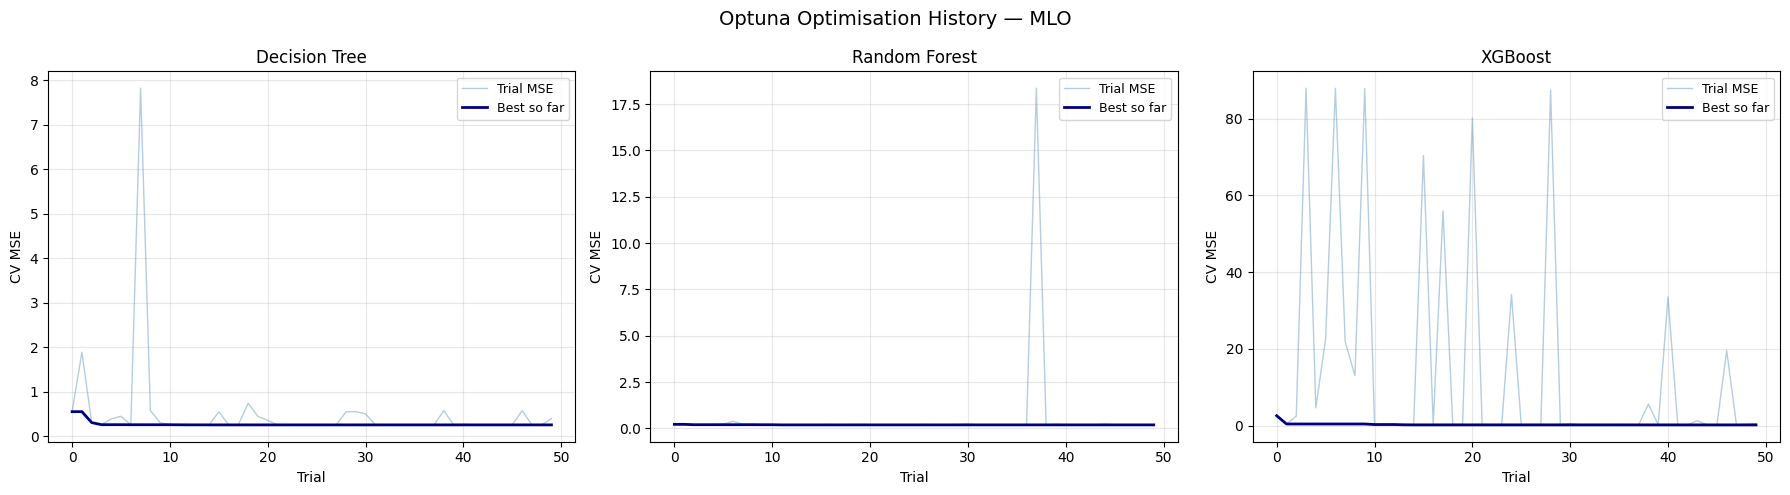

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 30 — OPTIMISATION HISTORY PLOTS (tree models)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'Optuna Optimisation History — {LOCATION}', fontsize=14)

for ax, study, name in zip(axes,
                            [dt_study, rf_study, xgb_study],
                            ['Decision Tree', 'Random Forest', 'XGBoost']):
    vals = [t.value for t in study.trials if t.value is not None]
    best = np.minimum.accumulate(vals)
    ax.plot(vals, color='steelblue', alpha=0.4, linewidth=1, label='Trial MSE')
    ax.plot(best, color='navy',      linewidth=2,             label='Best so far')
    ax.set_title(name, fontsize=12)
    ax.set_xlabel('Trial')
    ax.set_ylabel('CV MSE')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_History_{LOCATION}.png', dpi=150)
plt.show()

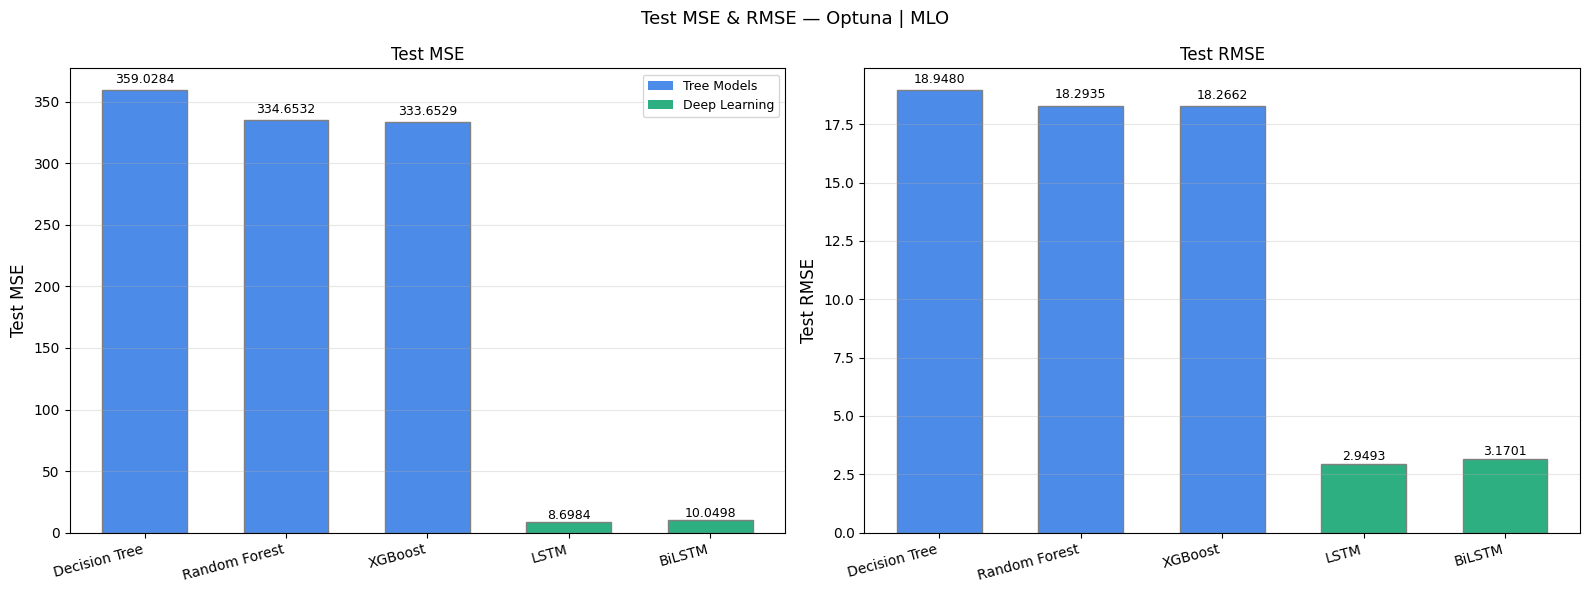

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 31 — MSE & RMSE BAR CHART (all 5 models)
# ─────────────────────────────────────────────────────────────
all_models = ['Decision Tree','Random Forest','XGBoost','LSTM','BiLSTM']
x = np.arange(len(all_models))

mse_vals  = [m['MSE']  for m in [dt_metrics,rf_metrics,xgb_metrics,lstm_metrics,bilstm_metrics]]
rmse_vals = [m['RMSE'] for m in [dt_metrics,rf_metrics,xgb_metrics,lstm_metrics,bilstm_metrics]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Test MSE & RMSE — Optuna | {LOCATION}', fontsize=13)

for ax, vals, lbl in [(ax1, mse_vals, 'Test MSE'), (ax2, rmse_vals, 'Test RMSE')]:
    bars = ax.bar(x, vals, 0.6, color=COLORS_ALL, edgecolor='grey')
    ax.set_ylabel(lbl, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(all_models, fontsize=10, rotation=15, ha='right')
    ax.set_title(lbl, fontsize=12)
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.01,
                f'{b.get_height():.4f}', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

ax1.legend(handles=LEGEND_ELEMS, fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_MSE_RMSE_{LOCATION}.png', dpi=150)
plt.show()

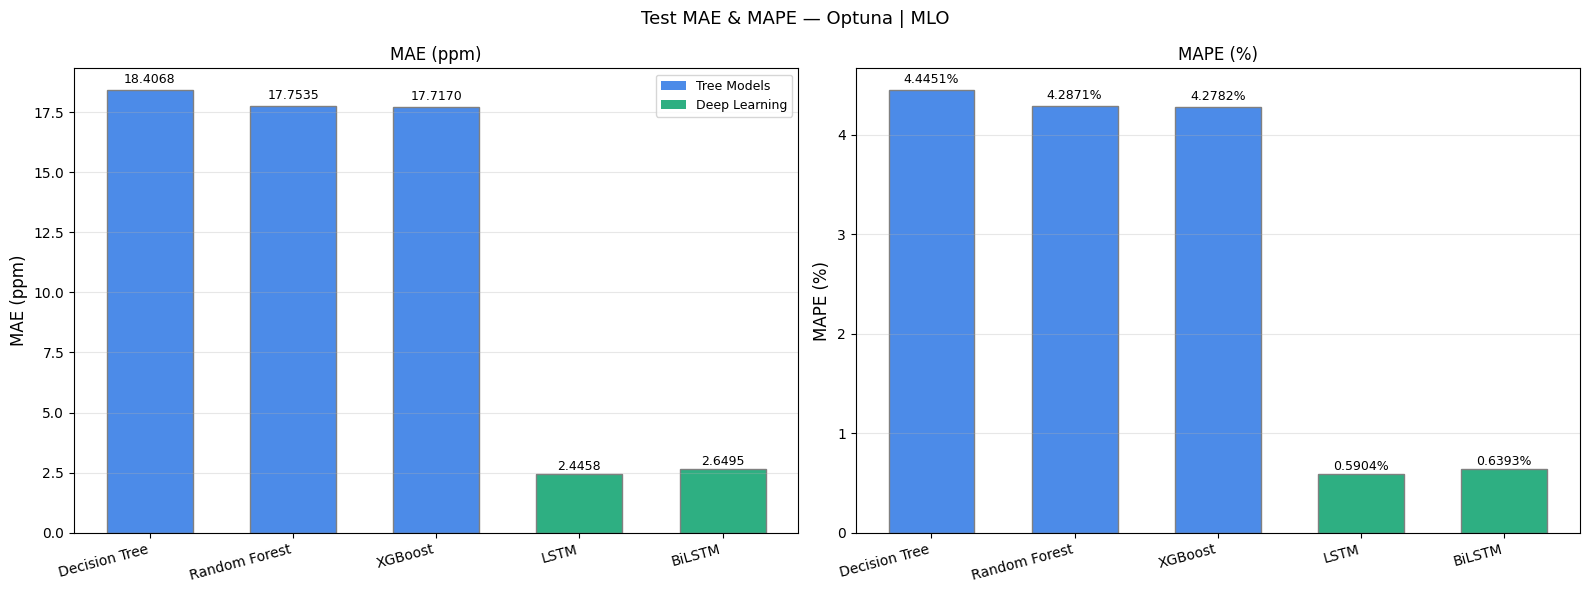

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 32 — MAE & MAPE BAR CHART (all 5 models)
# ─────────────────────────────────────────────────────────────
mae_vals  = [m['MAE']  for m in [dt_metrics,rf_metrics,xgb_metrics,lstm_metrics,bilstm_metrics]]
mape_vals = [m['MAPE'] for m in [dt_metrics,rf_metrics,xgb_metrics,lstm_metrics,bilstm_metrics]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Test MAE & MAPE — Optuna | {LOCATION}', fontsize=13)

for ax, vals, lbl, unit in [
    (ax1, mae_vals,  'MAE (ppm)',  ''),
    (ax2, mape_vals, 'MAPE (%)',   '%')
]:
    bars = ax.bar(x, vals, 0.6, color=COLORS_ALL, edgecolor='grey')
    ax.set_ylabel(lbl, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(all_models, fontsize=10, rotation=15, ha='right')
    ax.set_title(lbl, fontsize=12)
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.01,
                f'{b.get_height():.4f}{unit}', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

ax1.legend(handles=LEGEND_ELEMS, fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_MAE_MAPE_{LOCATION}.png', dpi=150)
plt.show()

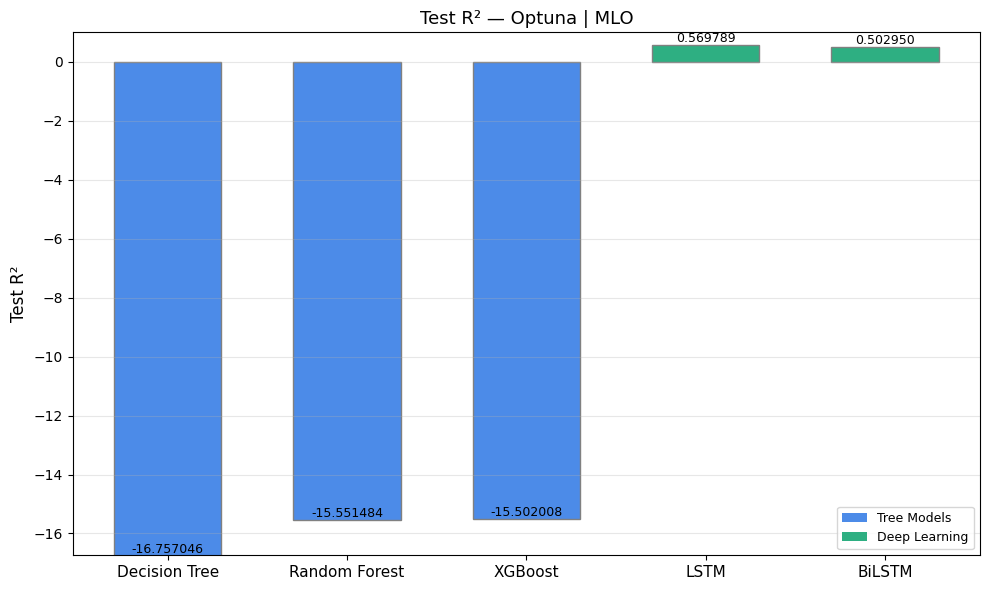

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 33 — R² BAR CHART (all 5 models)
# ─────────────────────────────────────────────────────────────
r2_vals = [m['R2'] for m in [dt_metrics,rf_metrics,xgb_metrics,lstm_metrics,bilstm_metrics]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(x, r2_vals, 0.6, color=COLORS_ALL, edgecolor='grey')
ax.set_ylabel('Test R²', fontsize=12)
ax.set_xticks(x); ax.set_xticklabels(all_models, fontsize=11)
ax.set_title(f'Test R² — Optuna | {LOCATION}', fontsize=13)
ax.set_ylim(min(r2_vals)*0.999, 1.001)
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.00005,
            f'{b.get_height():.6f}', ha='center', va='bottom', fontsize=9)
ax.legend(handles=LEGEND_ELEMS, fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_R2_{LOCATION}.png', dpi=150)
plt.show()

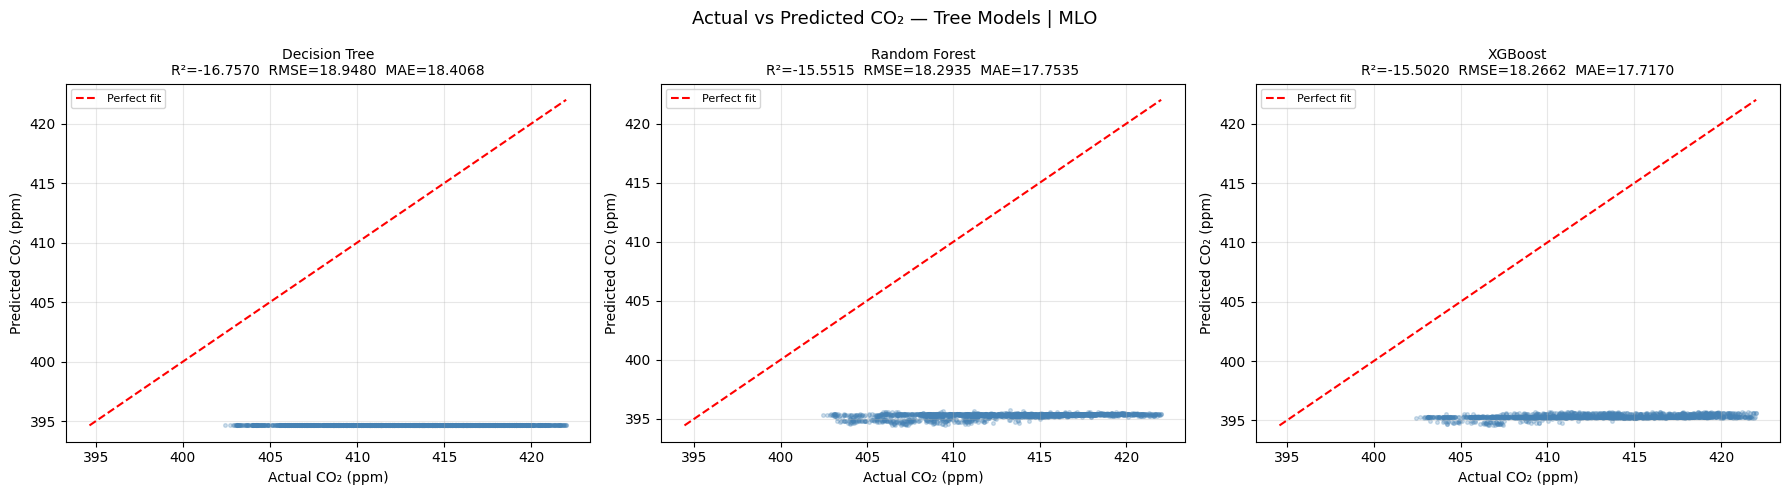

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 34 — ACTUAL vs PREDICTED (tree models)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'Actual vs Predicted CO₂ — Tree Models | {LOCATION}', fontsize=13)

for ax, y_pred, name, met in zip(
    axes,
    [y_pred_dt, y_pred_rf, y_pred_xgb],
    ['Decision Tree','Random Forest','XGBoost'],
    [dt_metrics, rf_metrics, xgb_metrics]
):
    ax.scatter(y_test, y_pred, alpha=0.25, s=7, color='steelblue')
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect fit')
    ax.set_xlabel('Actual CO₂ (ppm)', fontsize=10)
    ax.set_ylabel('Predicted CO₂ (ppm)', fontsize=10)
    ax.set_title(f'{name}\nR²={met["R2"]:.4f}  RMSE={met["RMSE"]:.4f}  MAE={met["MAE"]:.4f}', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_ActualVsPred_{LOCATION}.png', dpi=150)
plt.show()

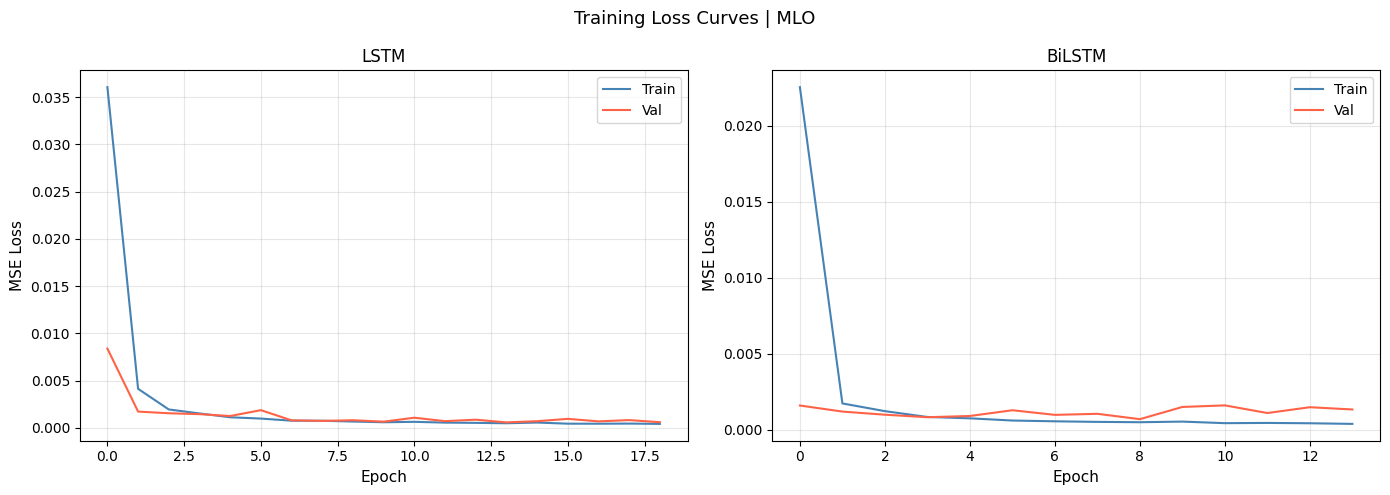

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 35 — LSTM / BiLSTM TRAINING LOSS CURVES
# ─────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Training Loss Curves | {LOCATION}', fontsize=13)

for ax, hist, name in [
    (ax1, hist_lstm,   'LSTM'),
    (ax2, hist_bilstm, 'BiLSTM')
]:
    ax.plot(hist.history['loss'],     label='Train', color='steelblue')
    ax.plot(hist.history['val_loss'], label='Val',   color='tomato')
    ax.set_title(name, fontsize=12)
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('MSE Loss', fontsize=11)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Optuna_LossCurves_{LOCATION}.png', dpi=150)
plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 36 — FINAL SUMMARY PRINT
# Clean one-glance output for paper reporting
# ─────────────────────────────────────────────────────────────
print(f'\n{"="*72}')
print(f'  COMPLETE RESULTS — {LOCATION} — Optuna Tuning')
print(f'{"="*72}')
print(f'{"Model":<16} {"MSE":>10} {"RMSE":>10} {"MAE":>10} {"MAPE%":>8} {"R²":>12}')
print('-'*72)
for _, row in results_summary.iterrows():
    print(f'{row["Model"]:<16} {row["MSE"]:>10.4f} {row["RMSE"]:>10.4f} '
          f'{row["MAE"]:>10.4f} {row["MAPE"]:>8.4f} {row["R2"]:>12.6f}')
print('='*72)
print(f'\nAll plots and CSV auto-saved to:')
print(f'  {OUTPUT_DIR}')
print(f'\nTo run BRW: set LOCATION = \'BRW\' in Cell 3 → Runtime → Run all')


  COMPLETE RESULTS — MLO — Optuna Tuning
Model                   MSE       RMSE        MAE    MAPE%           R²
------------------------------------------------------------------------
Decision Tree      359.0284    18.9480    18.4068   4.4451   -16.757046
Random Forest      334.6532    18.2935    17.7535   4.2871   -15.551484
XGBoost            333.6529    18.2662    17.7170   4.2782   -15.502008
LSTM                 8.6984     2.9493     2.4458   0.5904     0.569789
BiLSTM              10.0498     3.1701     2.6495   0.6393     0.502950

All plots and CSV auto-saved to:
  /content/drive/MyDrive/CO2-prediction-project/Optuna_Results_MLO

To run BRW: set LOCATION = 'BRW' in Cell 3 → Runtime → Run all
